# Type I seesaw with one active and two sterile neutrinos

$$M=\begin{pmatrix}0 & m_{D11} & m_{D12}\\ m_{D11} & M_1 & 0\\ m_{D12} & 0 & M_2\end{pmatrix},\qquad U^TMU=\mathrm{diag}(m_1,m_2,m_3).$$

**Assumptions**

* $M_R=\mathrm{diag}(M_1,M_2)$ with $0<M_1<M_2$. This is no loss of generality: a rotation of the sterile fields diagonalizes $M_R$ and is unobservable.
* Real case: $m_{D11},m_{D12}\in\mathbb{R}$.
* Complex case: $m_D=(r_{11},\ r_{12}e^{i\phi_{12}})$, $r_{1j}>0$. One phase is removed by rephasing $\nu_L$, and $n(m-1)=1$ **physical phase** remains — the first case in the series where CP violation is possible.

**Structure.** No massless states; $k=3$ massive states, so the characteristic polynomial is a cubic. It has three real roots, which makes Cardano's formula involve complex cube roots (casus irreducibilis); the trigonometric form is used instead. The matrix is an *arrowhead* matrix, for which the inverse problem has a closed form.

In [1]:
import os
import sys

# Make the ``src`` package importable (the notebook lives in ``notebooks/``)
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

import numpy as np
import sympy as sp
from sympy import (symbols, solve, sin, cos, tan, sqrt, exp, I, pi, Matrix,
                   conjugate, factor, simplify, init_printing)

from src.seesaw import SymbolicSeesawTypeI
from src.matrix_utils import (symbolic_rotation_matrix, sin_cos_from_tan_fraction,
                              simplify_with_mass_ordering, seesaw_block_expansion,
                              takagi_factorization)
from src.symbolic_diagonalization import *

init_printing()

## 1. Mass matrix and characteristic polynomial (real case)

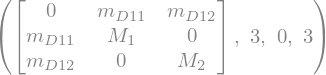

In [2]:
seesaw12 = SymbolicSeesawTypeI(n_generations=1, n_sterile=2, dirac='real', majorana_basis='diagonal')
mD = seesaw12.m_D_sym
a1, a2 = mD[0, 0], mD[0, 1]
M1, M2 = seesaw12.M_R_sym[0, 0], seesaw12.M_R_sym[1, 1]
mn = seesaw12.masses
m1, m2, m3 = mn
Mnu12 = seesaw12.full_mass_matrix_symbolic()
Mnu12, Mnu12.rank(), seesaw12.n_massless, seesaw12.n_massive

In [3]:
lamb = symbols('lambda', real=True)
charpoly = seesaw12.reduced_charpoly(lamb=lamb)
charpoly.as_expr().collect(lamb)

By Sylvester's law of inertia $M$ has the signature of $M_R$ (two positive eigenvalues) plus that of the Schur complement $-m_DM_R^{-1}m_D^T<0$ (one negative): $\lambda_1=-m_1$, $\lambda_2=m_2$, $\lambda_3=m_3$.

## 2. Direct solution: trigonometric roots of the cubic

With $\lambda=t-a/3$ the cubic becomes $t^3+pt+q=0$ and

$$t_k=2\sqrt{-\tfrac{p}{3}}\,\cos\!\left[\tfrac13\arccos\!\left(\tfrac{3q}{2p}\sqrt{-\tfrac{3}{p}}\right)-\tfrac{2\pi k}{3}\right],\qquad k=0,1,2 .$$

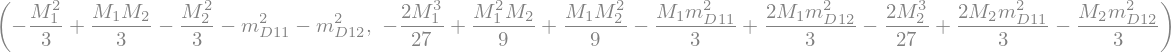

In [4]:
a_c, b_c, c_c = charpoly.all_coeffs()[1:]
p_c = sp.expand(b_c - a_c**2/3)
q_c = sp.expand(2*a_c**3/27 - a_c*b_c/3 + c_c)
p_c, q_c

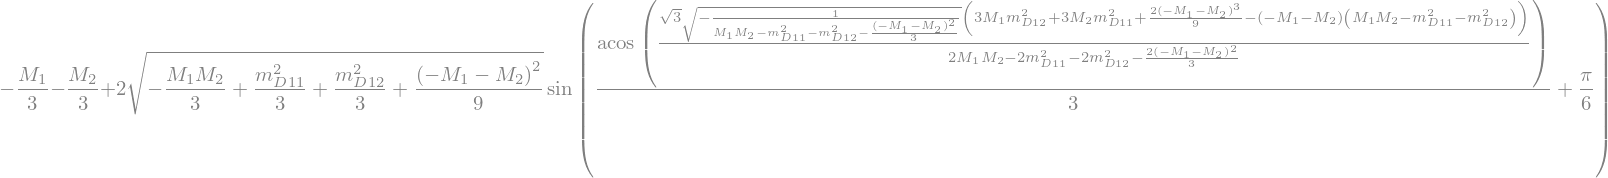

In [5]:
direct = direct_diagonalization(seesaw12)
direct['masses'][0]

The other two masses differ only by the shift $2\pi k/3$ inside the cosine. The mixing matrix follows from $\mathrm{adj}(M-\lambda_i)$; it is exact but already large:

In [6]:
U_direct = direct['U']
[sp.count_ops(mass) for mass in direct['masses']], sp.count_ops(U_direct)

In [7]:
verify_takagi(U_direct, Mnu12, direct['masses'], ranges={M1: (4.0, 5.0), M2: (7.0, 8.0)})

{'passed': True,
 'diagonalization_error': 5.38964333194548e-14,
 'unitarity_error': 5.371440909604688e-14,
 'mass_error': 6.715843578472274e-16,
 'n_points': 5,
 'precision': 'double'}

## 3. Semi-explicit form: mixing in terms of parameters and masses

Keeping the masses as symbols constrained by the cubic, the eigenvectors are simple. For an arrowhead matrix the eigenvector of $\lambda_j$ is

$$v_j\propto\left(1,\ \frac{m_{D11}}{\lambda_j-M_1},\ \frac{m_{D12}}{\lambda_j-M_2}\right)^T .$$

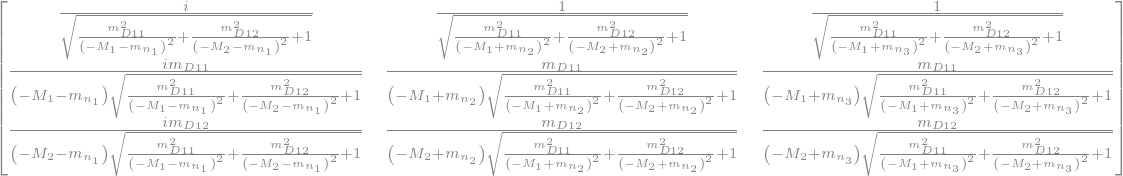

In [8]:
eigenvalues = [-m1, m2, m3]
U_semi = arrowhead_mixing_matrix(eigenvalues, [M1, M2], [a1, a2])
U_semi

The general-purpose routine (adjugate columns, valid for any $(n,m)$) gives the same matrix up to the sign of each column, together with the constraints $p(\lambda_j)=0$:

In [9]:
semi = semi_explicit_diagonalization(seesaw12)
semi['constraints']

## 4. Inverse problem: closed form from the arrowhead structure

Evaluating $\det(\lambda-M)=\prod_j(\lambda-\lambda_j)$ at $\lambda=M_i$ gives, for any number of sterile states,

$$m_{D1i}^2=-\frac{\prod_j(M_i-\lambda_j)}{\prod_{j\ne i}(M_i-M_j)},\qquad \sum_j\lambda_j=\sum_iM_i .$$

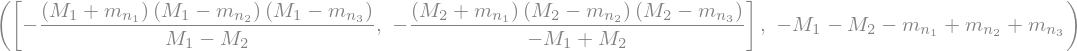

In [10]:
inverse = arrowhead_inverse_parameters(eigenvalues, [M1, M2])
inverse['m_D_squared'], inverse['trace_constraint']

The same relations come from matching the coefficients of the characteristic polynomial (linear in $m_{D1i}^2$):

In [11]:
eqs_charpoly = charpoly_matching_equations(seesaw12)
eqs_charpoly

In [12]:
matching_sol = solve(eqs_charpoly, [a1**2, a2**2, M2], dict=True)[0]
[simplify(matching_sol[a1**2] - inverse['m_D_squared'][0].subs(M2, matching_sol[M2])),
 simplify(matching_sol[a2**2] - inverse['m_D_squared'][1].subs(M2, matching_sol[M2])),
 matching_sol[M2]]

**Parameter counting.** $(m_{D11},m_{D12},M_1,M_2)\leftrightarrow(m_1,m_2,m_3)$ plus one mixing parameter, here $M_1$, with $M_2=m_2+m_3-m_1-M_1$. Positivity of $m_{D1i}^2$ is the interlacing condition

$$-m_1<M_1<m_2<M_2<m_3 .$$

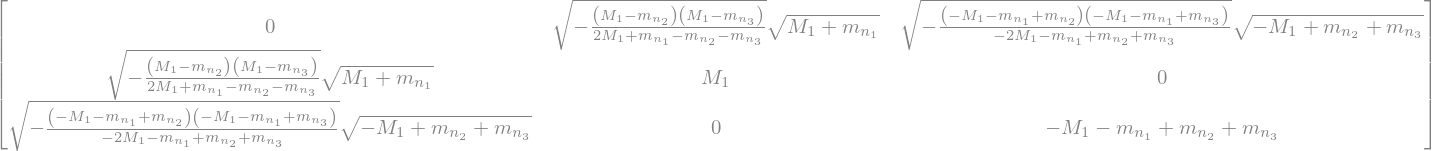

In [13]:
M2_sol = {M2: matching_sol[M2]}
mD_sol = {a1: sqrt(inverse['m_D_squared'][0]), a2: sqrt(inverse['m_D_squared'][1])}
Mnu12_masses = Mnu12.subs(mD_sol).subs(M2_sol)
U_masses = U_semi.subs(mD_sol).subs(M2_sol)
Mnu12_masses

In [14]:
def interlaced_point(m1_value, m2_value, m3_value, fraction):
    """Point with -m1 < M1 < m2 chosen by ``fraction`` in (0, 1), subject to M2 < m3."""
    low = max(-m1_value, m2_value - m1_value)   # M2 < m3  <=>  M1 > m2 - m1
    M1_value = low + fraction*(m2_value - low)
    return {m1: m1_value, m2: m2_value, m3: m3_value, M1: M1_value}

points = [interlaced_point(0.05, 2.0, 5.0, f) for f in (0.2, 0.5, 0.8)]
verify_takagi(U_masses, Mnu12_masses, [m1, m2, m3], points=points)

{'passed': True,
 'diagonalization_error': 3.5813645955650214e-16,
 'unitarity_error': 9.632134317267738e-16,
 'mass_error': 1.7906822977825107e-16,
 'n_points': 3,
 'precision': 'double'}

### Exact Casas–Ibarra form

Without choosing the sterile basis, the general solution is $X=i\,D^{-1/2}O\,d^{1/2}$ with $d=m_1$, $D=\mathrm{diag}(m_2,m_3)$ and $O=(\cos\omega,\sin\omega)^T$. The angle $\omega$ is the mixing parameter; $M_R$ comes out non-diagonal.

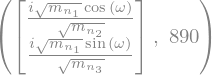

In [15]:
omega = symbols('omega', real=True)
O = Matrix([cos(omega), sin(omega)])
exact = exact_seesaw_parametrization([m1], [m2, m3], O, real=True)
exact['X'], sp.count_ops(exact['M'])

In [16]:
mass_ranges = {m1: (0.01, 0.1), m2: (1.0, 2.0), m3: (3.0, 5.0)}
verify_takagi(exact['U'], exact['M'], [m1, m2, m3], ranges={**mass_ranges, omega: (-3.1, 3.1)})

{'passed': True,
 'diagonalization_error': 4.0476790451735493e-16,
 'unitarity_error': 3.3306690738754696e-16,
 'mass_error': 2.0238395225867747e-16,
 'n_points': 5,
 'precision': 'double'}

By unitarity the active–heavy mixing is $|U_{e2}|^2+|U_{e3}|^2=1-|U_{e1}|^2=\dfrac{X^\dagger X}{1+X^\dagger X}$ with $X^\dagger X=m_1\left(\dfrac{\cos^2\omega}{m_2}+\dfrac{\sin^2\omega}{m_3}\right)$:

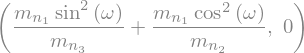

In [17]:
XdX = simplify((exact['X'].H*exact['X'])[0, 0])
XdX, simplify(exact['U'][0, 0]*conjugate(exact['U'][0, 0]) - 1/(1 + XdX))

## 5. Complex case: one physical phase

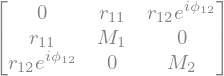

In [18]:
seesaw12c = SymbolicSeesawTypeI(n_generations=1, n_sterile=2, dirac='polar', majorana_basis='diagonal')
Mnu12c = seesaw12c.full_mass_matrix_symbolic()
r11, r12 = seesaw12c.dirac_moduli
phi12 = seesaw12c.dirac_phases[0, 1]
Mnu12c

The squared masses are the roots of $\det(\lambda-M^\dagger M)$, again a cubic. Its coefficients now depend on $\phi_{12}$, e.g. $\det M^\dagger M=|m_{D11}^2M_2+m_{D12}^2M_1|^2$, so the masses themselves depend on the phase: it cannot be rotated away.

In [19]:
charpoly_c = seesaw12c.reduced_charpoly(hermitian_square=True, lamb=lamb)
[simplify(sp.expand(coefficient).rewrite(cos)) for coefficient in charpoly_c.all_coeffs()]

In [20]:
direct_c = direct_diagonalization(seesaw12c)
sp.count_ops(direct_c['U'])

In [21]:
verify_takagi(direct_c['U'], Mnu12c, direct_c['masses'],
              ranges={M1: (4.0, 5.0), M2: (7.0, 8.0), phi12: (-3.1, 3.1)})

{'passed': True,
 'diagonalization_error': 1.0014407501900784e-14,
 'unitarity_error': 7.37188088351104e-14,
 'mass_error': 1.511902395015169e-15,
 'n_points': 5,
 'precision': 'double'}

The direct Takagi matrix is exact and verified, but considerably larger than in the real case. The inverse problem stays compact: the same exact parametrization with a *complex* angle $\omega\to z$ ($O^TO=1$ still holds) covers the complex case, the imaginary part of $z$ carrying the CP phase.

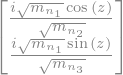

In [22]:
z = symbols('z')
O_c = Matrix([cos(z), sin(z)])
exact_c = exact_seesaw_parametrization([m1], [m2, m3], O_c)
exact_c['X']

In [23]:
verify_takagi(exact_c['U'], exact_c['M'], [m1, m2, m3], ranges=mass_ranges)

{'passed': True,
 'diagonalization_error': 2.1777603431352124e-16,
 'unitarity_error': 3.3306690738754696e-16,
 'mass_error': 4.35551951802921e-16,
 'n_points': 5,
 'precision': 'double'}

## 6. Seesaw expansion

$m_\nu=-\left(\dfrac{m_{D11}^2}{M_1}+\dfrac{m_{D12}^2}{M_2}\right)+\dots$ The exact light mass is compared numerically with the expansion at orders 2, 4, 6 in $\epsilon\sim m_D/M_R$; the relative error falls as $\epsilon^2,\epsilon^4,\epsilon^6$.

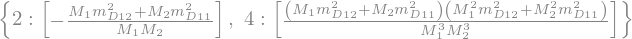

In [24]:
expansion = {order: seesaw_block_expansion(mD, seesaw12.M_R_sym, order=order) for order in (2, 4, 6)}
{power: term.applyfunc(factor) for power, term in expansion[4]['light_terms'].items()}

In [25]:
import pandas as pd

arguments = [a1, a2, M1, M2]
exact_light = sp.lambdify(arguments, direct['masses'][0], 'numpy')
approx_light = {order: sp.lambdify(arguments, -expansion[order]['m_light'][0, 0], 'numpy')
                for order in expansion}
rows = []
for eps in (0.4, 0.2, 0.1):
    point = (0.7*eps, 1.1*eps, 1.0, 2.5)
    reference = float(np.real(exact_light(*[complex(x) for x in point])))
    rows.append({'epsilon': eps, 'exact m_1': reference,
                 **{f'rel. error O(eps^{order})': abs(approx_light[order](*point)/reference - 1)
                    for order in expansion}})
pd.DataFrame(rows)

,epsilon,exact m_1,rel. error O(eps^2),rel. error O(eps^4),rel. error O(eps^6)
0,0.4,0.141935,0.097967,0.022124,0.006546
1,0.2,0.037954,0.026511,0.001557,0.000118
2,0.1,0.009674,0.006782,0.000101,0.000002


## Summary

| quantity | result |
|:--|:--|
| massive states | 3, roots of a cubic (trigonometric form) |
| direct mixing matrix | exact, verified; large (real) / very large (complex) |
| semi-explicit mixing | $v_j\propto(1,\ m_{D11}/(\lambda_j-M_1),\ m_{D12}/(\lambda_j-M_2))$ |
| inverse problem | closed form: $m_{D1i}^2=-\prod_j(M_i-\lambda_j)/\prod_{j\neq i}(M_i-M_j)$, $\ \sum_j\lambda_j=\sum_iM_i$ |
| physical phases | 1 (masses depend on $\phi_{12}$) |

The arrowhead formulas hold for $(1,m)$ with any $m$, so in the inverse direction one active neutrino never hits a feasibility limit; see `seesaw_1_active_3_sterile.ipynb`.